# Flight CSV envelope viewer

Loads a Kompic flight CSV (format v1) and renders a min/max
envelope + median trace per channel so a multi-minute capture at
125 Hz stays legible without downsampling.

- Set `CSV_PATH` below and `Run All`.
- `N_WINDOWS` controls envelope resolution: ~500 is a sweet spot
  for ~1 hr of recording; drop to 100 for second-scale detail.
- IMU (accel + gyro) is dense; mag/env/GPS are sparse channels
  carried forward between fresh samples, so their traces look
  stair-steppy by design.

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from flight_csv import load, CHANNEL_GROUPS

# Default: the first sample capture Ivan dropped into reference_files.
CSV_PATH = Path(
    "/home/ivan/Projekti/Elektronika/Kompic-Wearable/kompic-wearable/docs/build_info/reference_files/kompic_data/2026-10-05/flight/kompic_2026-10-05_00-27-50_flight.csv"
)
N_WINDOWS = 500

df, meta = load(CSV_PATH)
print(f"loaded {len(df)} rows from {CSV_PATH.name}")
for k in ("device_hw", "device_fw", "record_start_utc",
         "sample_rate_hz", "rtc_valid_at_start"):
    print(f"  {k:22s} = {meta.get(k, '--')}")

loaded 3391 rows from kompic_2026-10-05_00-27-50_flight.csv
  device_hw              = iv8.0
  device_fw              = 0.4.99
  record_start_utc       = 2026-10-05T00:27:50
  sample_rate_hz         = 125
  rtc_valid_at_start     = 1


In [4]:
# Quick sanity: duration + nominal sample rate from timestamps.
dur_s = df['t_s'].iloc[-1]
actual_hz = len(df) / dur_s if dur_s > 0 else float('nan')
print(f"duration       : {dur_s:7.2f} s  ({dur_s/60:.2f} min)")
print(f"nominal rate   : {meta.get('sample_rate_hz', '?')} Hz")
print(f"actual rate    : {actual_hz:7.2f} Hz")
print(f"mag_fresh frac : {df['mag_fresh'].mean():7.3f}")
print(f"env_fresh frac : {df['env_fresh'].mean():7.3f}")
if 'gps_fix' in df.columns:
    fix_counts = df['gps_fix'].value_counts().to_dict()
    print(f"gps_fix hist   : {fix_counts}")

duration       :   41.94 s  (0.70 min)
nominal rate   : 125 Hz
actual rate    :   80.86 Hz
mag_fresh frac :   0.000
env_fresh frac :   0.006
gps_fix hist   : {0: 3391}


In [5]:
def envelope(series: pd.Series, t: pd.Series, n: int = N_WINDOWS):
    """Bin ``series`` into ``n`` time windows, return (centre_t, lo, mid, hi).

    - lo/hi: window min/max (the envelope band)
    - mid: window median
    Windows with no samples are dropped. Blank-only windows (all NaN)
    also drop out silently.
    """
    if len(series) == 0:
        return np.array([]), np.array([]), np.array([]), np.array([])
    bins = np.linspace(t.iloc[0], t.iloc[-1], n + 1)
    idx = np.digitize(t.values, bins) - 1
    idx = np.clip(idx, 0, n - 1)
    d = pd.DataFrame({'bin': idx, 'v': series.values, 't': t.values})
    g = d.dropna(subset=['v']).groupby('bin')
    tc = g['t'].mean()
    lo = g['v'].min()
    hi = g['v'].max()
    mid = g['v'].median()
    return tc.values, lo.values, mid.values, hi.values

def plot_group(cols, title, ylabel):
    present = [c for c in cols if c in df.columns and df[c].notna().any()]
    if not present:
        print(f"skip {title}: no non-NaN data")
        return
    # Collapse all-zero channels (e.g. mag when LIS is stubbed) so the
    # subplot still renders but axes aren't cluttered by flat lines.
    nonzero = [c for c in present if (df[c].abs() > 1e-9).any()]
    plot_cols = nonzero if nonzero else present
    fig, ax = plt.subplots(len(plot_cols), 1, sharex=True,
                           figsize=(11, 1.6 * len(plot_cols) + 1))
    if len(plot_cols) == 1:
        ax = [ax]
    for a, c in zip(ax, plot_cols):
        tc, lo, mid, hi = envelope(df[c], df['t_s'])
        a.fill_between(tc, lo, hi, alpha=0.25, linewidth=0,
                       label='min\u2013max')
        a.plot(tc, mid, linewidth=0.8, label='median')
        a.set_ylabel(c)
        a.grid(True, alpha=0.3)
    ax[0].set_title(f"{title}  --  {len(df)} rows, {df['t_s'].iloc[-1]:.1f} s")
    ax[-1].set_xlabel('t (s)')
    ax[0].legend(loc='upper right', fontsize=8)
    fig.tight_layout()
    plt.show()

## Accel (LSM6DSV16X, dense @ ~125 Hz)

Double-tap sync spikes land here as sharp min/max band spreads --
the median line stays near 1 g on `az_mg` at rest.

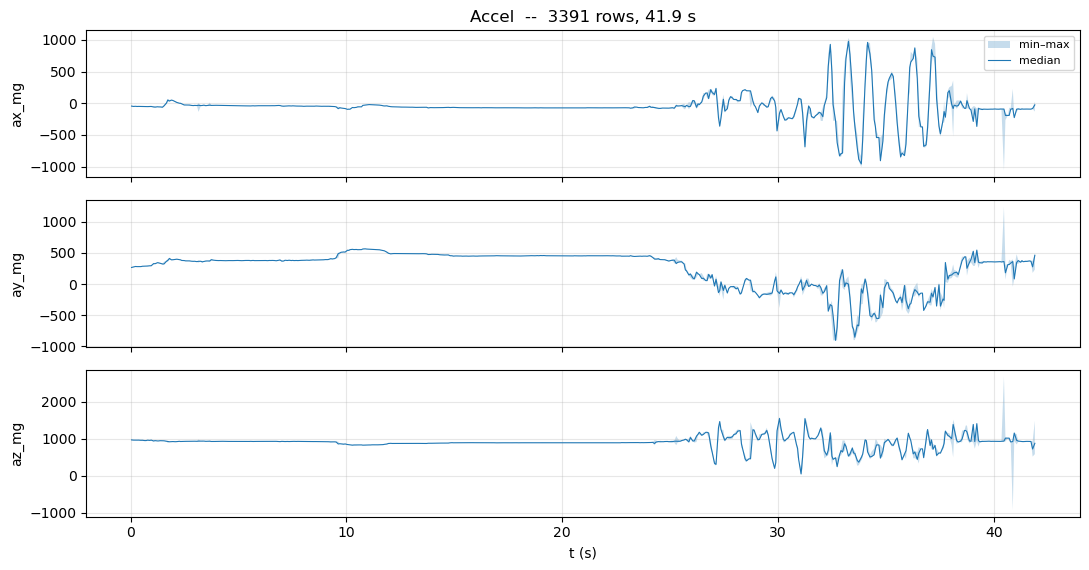

In [6]:
plot_group(CHANNEL_GROUPS['accel (mg)'], 'Accel', 'mg')

## Gyro (LSM6DSV16X, dense @ ~125 Hz)

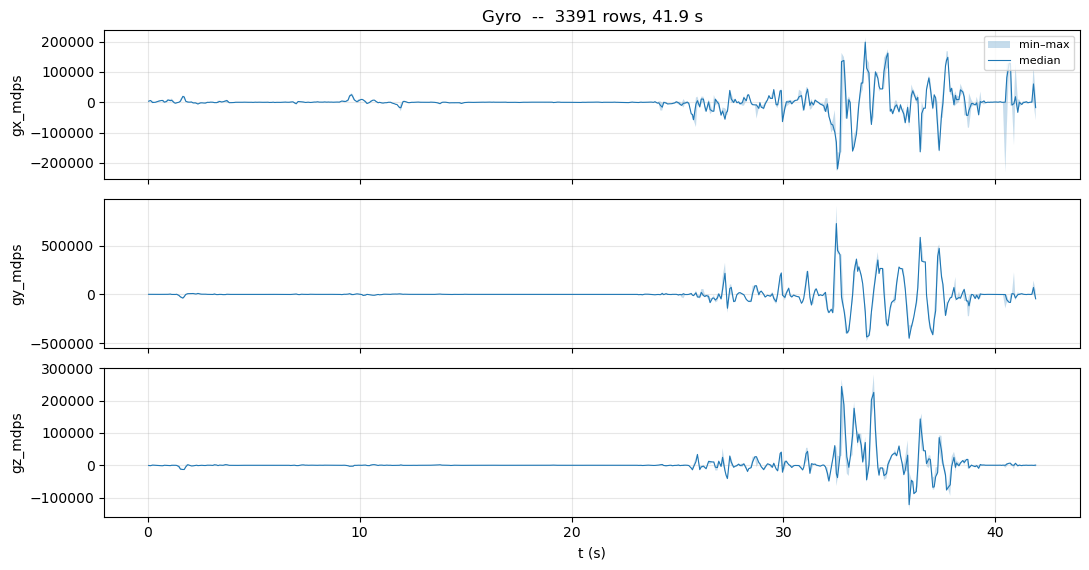

In [7]:
plot_group(CHANNEL_GROUPS['gyro (mdps)'], 'Gyro', 'mdps')

## Mag (LIS3MDL, sparse)

LIS is stubbed out in Stage 35 builds -- expect all zeros until the
driver returns. The envelope cell quietly skips flat lines.

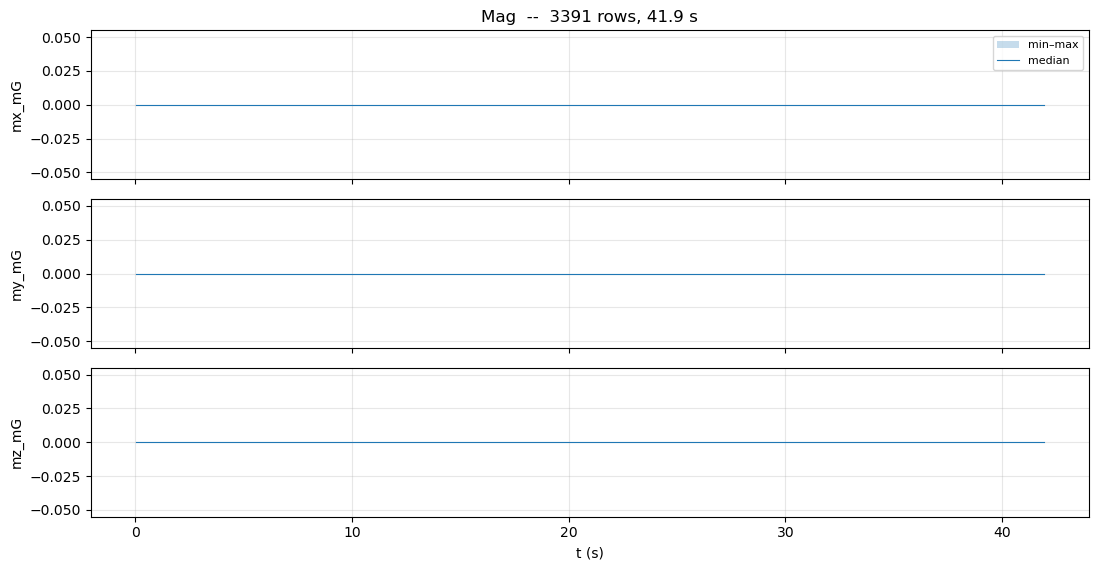

In [8]:
plot_group(CHANNEL_GROUPS['mag (mG)'], 'Mag', 'mG')

## Env (BME688, forced-mode ~1 Hz)

Pressure trace is the altitude proxy; temperature + humidity +
gas-resistance come from the same forced-mode cycle.

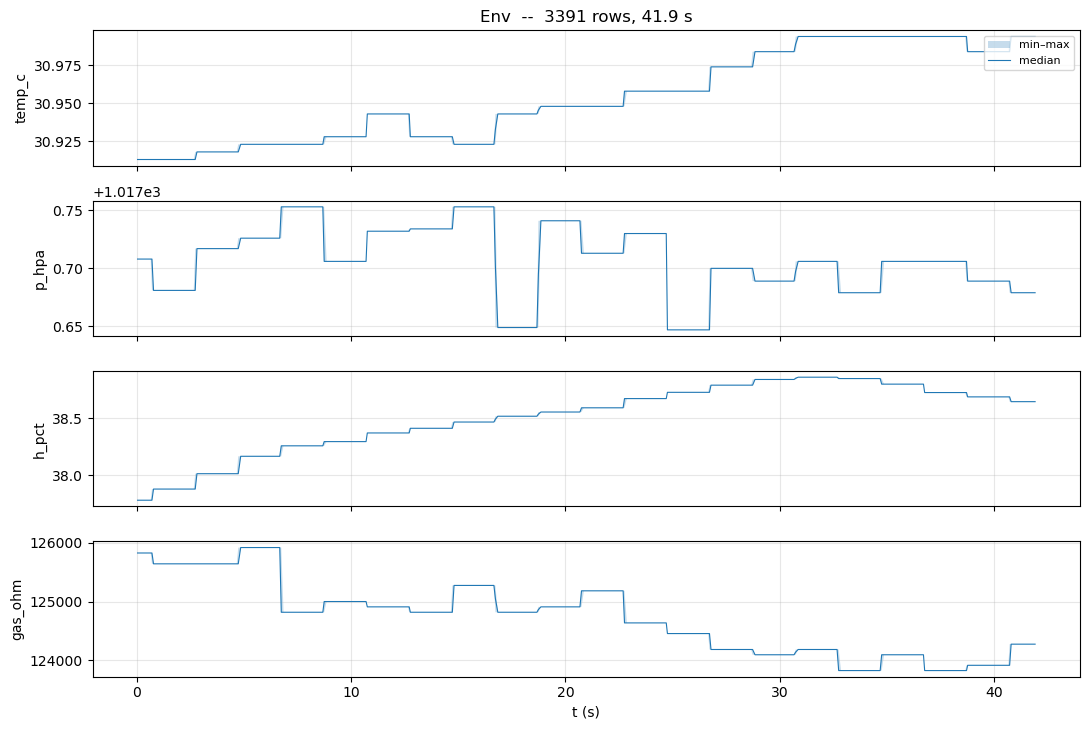

In [9]:
plot_group(CHANNEL_GROUPS['env'], 'Env', 'mixed')

## GPS (MAX-M10S, sparse; blank until fix)

Only plotted if the file has at least one 2D or 3D fix row --
otherwise skips.

In [10]:
if 'gps_fix' in df.columns and (df['gps_fix'] >= 2).any():
    plot_group(CHANNEL_GROUPS['gps'], 'GPS', 'deg / m')
else:
    print('no GPS fix in file -- skipping')

no GPS fix in file -- skipping


## Accel magnitude (|a|) -- useful for spotting the sync double-taps

The CSV is time-stamped so you can match these spikes to video
timecodes post-flight.

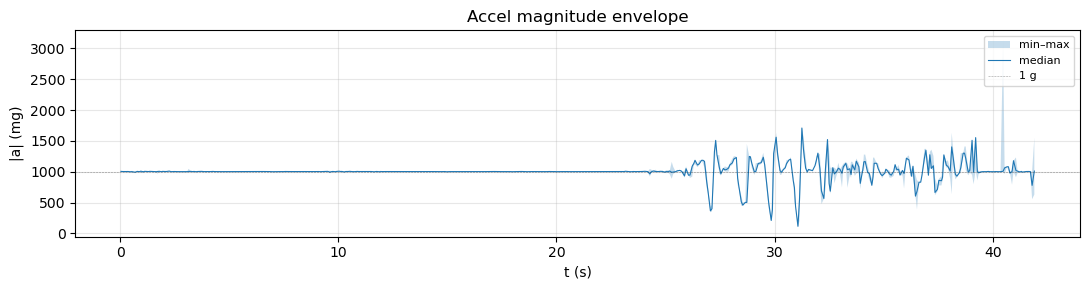

top 10 accel peaks:
  t=  40.50 s   |a|= 3140.3 mg
  t=  40.51 s   |a|= 3140.3 mg
  t=  40.52 s   |a|= 3140.3 mg
  t=  40.52 s   |a|= 3140.3 mg
  t=  40.53 s   |a|= 3140.3 mg
  t=  40.54 s   |a|= 3140.3 mg
  t=  31.24 s   |a|= 1714.3 mg
  t=  31.25 s   |a|= 1714.3 mg
  t=  31.26 s   |a|= 1714.3 mg
  t=  31.27 s   |a|= 1714.3 mg


In [11]:
a_mag = np.sqrt(df['ax_mg']**2 + df['ay_mg']**2 + df['az_mg']**2)
tc, lo, mid, hi = envelope(a_mag, df['t_s'])
fig, ax = plt.subplots(figsize=(11, 3))
ax.fill_between(tc, lo, hi, alpha=0.25, linewidth=0, label='min\u2013max')
ax.plot(tc, mid, linewidth=0.8, label='median')
ax.axhline(1000.0, color='k', linewidth=0.4, linestyle='--',
           alpha=0.4, label='1 g')
ax.set_ylabel('|a| (mg)')
ax.set_xlabel('t (s)')
ax.set_title('Accel magnitude envelope')
ax.grid(True, alpha=0.3)
ax.legend(loc='upper right', fontsize=8)
fig.tight_layout()
plt.show()

# Also print the top 10 brightest peaks for a quick numeric glance
# at candidate sync events.
pk = a_mag.rolling(5).max()
idx = pk.nlargest(10).index
print('top 10 accel peaks:')
for i in idx:
    print(f"  t={df['t_s'].iloc[i]:7.2f} s   |a|={pk.iloc[i]:7.1f} mg")